# 05 - Classificação com FCNN (Fully Convolutional Network)

Rede só com convoluções. Em vez de `Flatten` + `Dense`, uma convolução 1x1 gera 4 mapas (um para cada classe) e o `GlobalAveragePooling2D` tira a média de cada mapa. Esses 4 valores vão para a softmax. Sem camadas densas, a rede tem bem menos parâmetros que a CNN.

Os dados e a divisão treino/validação são os mesmos do `05_cnn_classification.ipynb`. A avaliação no conjunto de teste está no `06_metrics.ipynb`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Activation

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
tf.keras.utils.set_random_seed(0)
print(tf.config.list_physical_devices('GPU'))

I0000 00:00:1795056971.269903  185164 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Carregamento dos dados

In [2]:
splits = pd.read_csv(PROJECT_ROOT / 'data' / 'annotations' / 'splits.csv')
classes = sorted(splits['classe'].unique())
print(classes)

def carregar(conjunto):
    df = splits[splits['conjunto'] == conjunto]
    X, y = [], []
    for _, row in df.iterrows():
        caminho = PROJECT_ROOT / row['caminho'].replace('spectrograms', 'mod_spectograms')
        img = Image.open(caminho).convert('RGB').resize((224, 224))
        X.append(np.array(img) / 255.0)
        y.append(classes.index(row['classe']))
    return np.array(X, dtype='float32'), np.array(y)

X_train, y_train = carregar('treino')
X_val, y_val = carregar('validacao')
print(X_train.shape, X_val.shape)

def plotar_historico(history, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metrica, nome in zip(axes, ['loss', 'accuracy'], ['Perda', 'Acurácia']):
        ax.plot(history.history[metrica], label='Treinamento')
        ax.plot(history.history['val_' + metrica], label='Validação')
        ax.set_title(f'{titulo} — {nome}')
        ax.set_xlabel('Épocas')
        ax.set_ylabel(metrica)
        ax.legend()
    plt.tight_layout()
    plt.show()

['ICTAL', 'NORMAL', 'POS_ICTAL', 'PRE_ICTAL']
(100, 224, 224, 3) (20, 224, 224, 3)


## Arquitetura

In [3]:
fcnn = Sequential([
    Input(shape=(224, 224, 3)),
    Conv2D(16, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Conv2D(4, (1, 1)),          # 1 mapa por classe
    GlobalAveragePooling2D(),   # média de cada mapa -> 4 valores
    Activation('softmax'),
])

fcnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 4)      │           260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 4)              │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 4)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,844 (93.14 KB)

 Trainable params: 23,844 (93.14 KB)

 Non-trainable params: 0 (0.00 B)

## Treinamento

In [4]:
fcnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_fcnn = fcnn.fit(X_train, y_train, epochs=30, validation_data=(X_val, y_val), verbose=2)

Epoch 1/30
4/4 - 8s - 2s/step - accuracy: 0.2200 - loss: 1.3892 - val_accuracy: 0.2500 - val_loss: 1.3771
Epoch 2/30
4/4 - 0s - 31ms/step - accuracy: 0.2300 - loss: 1.3832 - val_accuracy: 0.2500 - val_loss: 1.3674
Epoch 3/30
4/4 - 0s - 31ms/step - accuracy: 0.2500 - loss: 1.3814 - val_accuracy: 0.2500 - val_loss: 1.3596
Epoch 4/30
4/4 - 0s - 37ms/step - accuracy: 0.2500 - loss: 1.3800 - val_accuracy: 0.2500 - val_loss: 1.3503
Epoch 5/30
4/4 - 0s - 30ms/step - accuracy: 0.2500 - loss: 1.3787 - val_accuracy: 0.2500 - val_loss: 1.3400
Epoch 6/30
4/4 - 0s - 31ms/step - accuracy: 0.2500 - loss: 1.3781 - val_accuracy: 0.2500 - val_loss: 1.3298
Epoch 7/30
4/4 - 0s - 35ms/step - accuracy: 0.2500 - loss: 1.3785 - val_accuracy: 0.2500 - val_loss: 1.3226
Epoch 8/30
4/4 - 0s - 32ms/step - accuracy: 0.2500 - loss: 1.3794 - val_accuracy: 0.3000 - val_loss: 1.3189
Epoch 9/30
4/4 - 0s - 36ms/step - accuracy: 0.2500 - loss: 1.3795 - val_accuracy: 0.4000 - val_loss: 1.3184
Epoch 10/30
4/4 - 0s - 32ms/st

## Gráficos

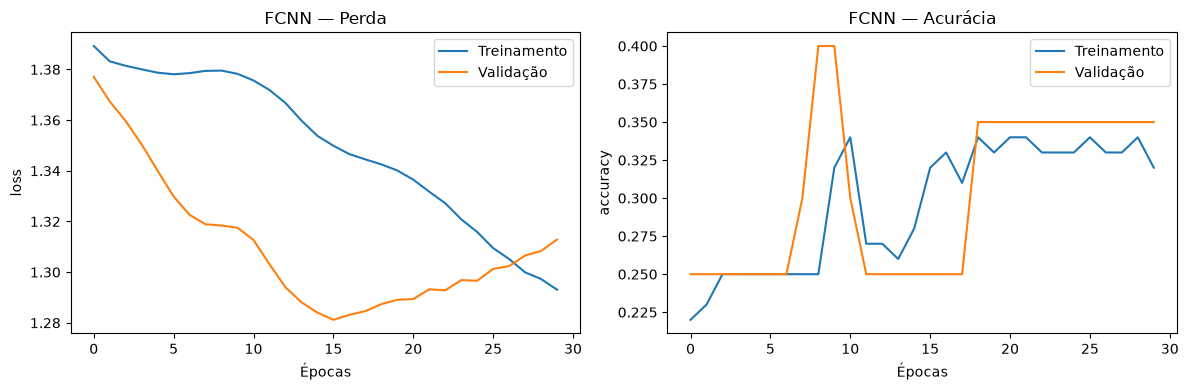

In [5]:
plotar_historico(history_fcnn, 'FCNN')

## Resultados (FCNN)

Aqui acontece o contrário da CNN. A loss de treino cai devagar, de 1,39 para 1,29, e a acurácia de treino sai de 22% e termina em 32% (máximo de 34%). A validação acompanha o treino: a acurácia fica entre 25% e 40% e termina em 35%, e a loss de validação fica perto de 1,30.

Não tem overfitting, o problema é underfitting. Com cerca de 24 mil parâmetros e 30 épocas, a rede ainda não conseguiu separar as classes, e a loss quase não sai do valor inicial de ln 4 ≈ 1,386 (25% para cada classe). Daria para testar mais épocas ou uma taxa de aprendizado maior.

## Salvando o modelo

In [6]:
fcnn.save(PROJECT_ROOT / 'models' / 'modelo_fcnn.keras')

## Próximo passo

A avaliação no conjunto de teste está no notebook `06_metrics.ipynb`.